In [1]:
import pandas as pd
import json
import plotly.express as px
import numpy as np

# Preprocessing

In [2]:
# Load chiller_plant_dataset.parquet
chiller_data = pd.read_parquet('data/chiller_plant_dataset.parquet')

with open('data/columns_info.json') as f:
    columns_info = json.load(f)

In [3]:
# Drop columns
import ast

column_list = chiller_data.columns.to_list()
columns_info_list = []
for key in columns_info:
    tup = ast.literal_eval(key)
    columns_info_list.append(tup)
columns_to_drop = [col for col in column_list if col not in columns_info_list]
columns_to_drop.append(('chiller_6', 'power'))
chiller_data = chiller_data.drop(columns=columns_to_drop)
chiller_data.shape

(77014, 191)

In [4]:
# Remove NaN
chiller_data.ffill(inplace=True)
chiller_data.bfill(inplace=True)
chiller_data.isnull().sum().sum()

np.int64(0)

In [5]:
# Remove negative values
# Check which columns have negative values
negative_columns = chiller_data.columns[chiller_data.lt(0).any()]

# Count negative values in each column
negative_counts = chiller_data[negative_columns].lt(0).sum().sum()

print("negative values:")
print(negative_counts)

# Replace negative values with NaN
chiller_data[negative_columns] = chiller_data[negative_columns].mask(chiller_data[negative_columns] < 0)
# Forward fill NaN values
chiller_data.ffill(inplace=True)
chiller_data.bfill(inplace=True)

# Verify if negative values are replaced
negative_counts_after_fill = chiller_data[negative_columns].lt(0).sum().sum()

print("negative values after forward filling:")
print(negative_counts_after_fill)

negative values:
12838
negative values after forward filling:
0


In [6]:
# Change Multidexing to normal columns name
chiller_data.columns = ['_'.join(col) if isinstance(col, tuple) else col for col in chiller_data.columns]

In [7]:
# Add two feature
## New day
def extract_day(date_str):
    return date_str.split()[0]

# Create a new column with the extracted day
chiller_data['day'] = chiller_data.index.map(extract_day)

# Create the 'new_day' feature
chiller_data['new_day'] = (chiller_data['day'] != chiller_data['day'].shift(1)).astype(int)

# Drop the temporary 'day' column
chiller_data.drop(columns=['day'], inplace=True)

# Display the first few rows to check the new feature
print(chiller_data[['new_day']].head(10))

## Pumps power
chiller_data['plant_power_all_pumps'] = chiller_data['plant_power_all_chps'] + chiller_data['plant_power_all_cdps']

                           new_day
datetime                          
2023-01-01 23:45:00+07:00        1
2023-01-01 23:50:00+07:00        0
2023-01-01 23:55:00+07:00        0
2023-01-02 00:00:00+07:00        1
2023-01-02 00:05:00+07:00        0
2023-01-02 00:10:00+07:00        0
2023-01-02 00:15:00+07:00        0
2023-01-02 00:20:00+07:00        0
2023-01-02 00:25:00+07:00        0
2023-01-02 00:30:00+07:00        0


In [8]:
# save preprocessed data
chiller_data.to_parquet('chiller_data_pre.parquet')

# Load preprocessed data

In [9]:
chiller_data = pd.read_parquet('chiller_data_pre.parquet')

# Sys iden

# Cdps

### Linear Regression

Linear Regression MSE: 215.56034290301685
Linear Regression MAE: 8.19212754381155
Linear Regression R²: 0.8434124201435804
Linear Regression CvRMSE: 0.353177355957206


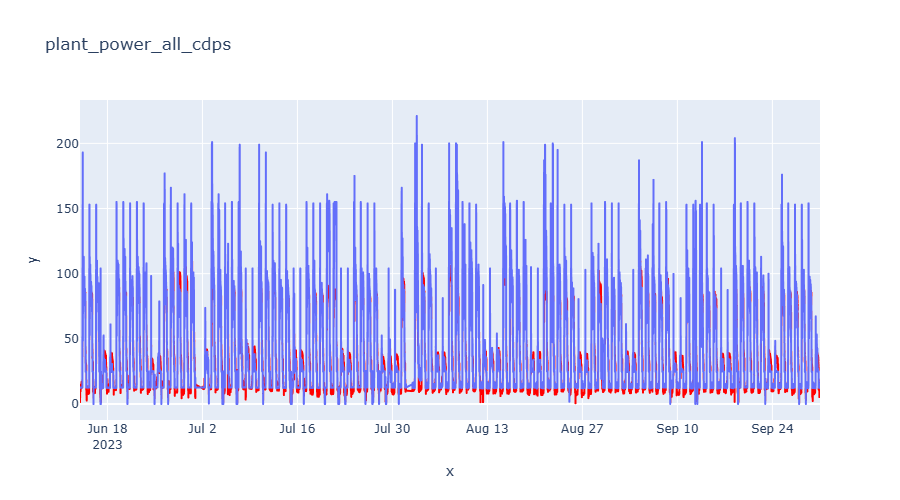

In [10]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

cdps_feature = ['plant_cooling_rate'] + \
                [f'chiller_{i}_cond_water_flow_rate' for i in range(1, 6)]

cdps_target = ['plant_power_all_cdps']

X = chiller_data[cdps_feature]
y = chiller_data[cdps_target]

train_size = int(0.6 * len(X))
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

# Train the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)


# Predict
y_pred_lr = lr_model.predict(X_test)
y_pred_lr = y_pred_lr.clip(min=0)

# Performance Metrics
mse_lr = mean_squared_error(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

def cvrmse(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return rmse / np.mean(y_true)

cvrmse_lr = cvrmse(y_test, y_pred_lr)

# Print metrics
print(f"Linear Regression MSE: {mse_lr}")
print(f"Linear Regression MAE: {mae_lr}")
print(f"Linear Regression R²: {r2_lr}")
print(f"Linear Regression CvRMSE: {cvrmse_lr}")

# Plotting
y_pred_lr_df = pd.DataFrame(y_pred_lr, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=y_pred_lr_df[cdps_target[0]], title=f'{cdps_target[0]}')
fig.update_traces(line_color='red', name=f'{cdps_target[0]}')
fig.add_trace(px.line(x=X_test.index, y=y_test[cdps_target[0]]).data[0])
fig.show()

### Random forest

Random Forest MSE: 29.79459604803981
Random Forest MAE: 2.2731487420266
Random Forest R²: 0.9783565769791838
Random Forest CvRMSE: 0.1313037618709566


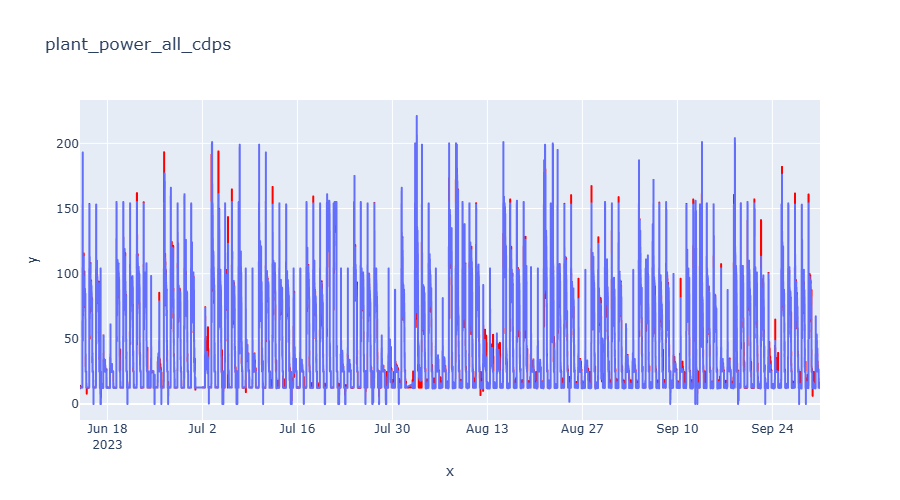

In [11]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

cdps_feature = ['plant_cooling_rate'] + \
               [f'chiller_{i}_cond_water_flow_rate' for i in range(1, 6)]

cdps_target = ['plant_power_all_cdps']

X = chiller_data[cdps_feature]
y = chiller_data[cdps_target]

train_size = int(0.6 * len(X))
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

# Train the model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train.values.ravel())

# Predict
y_pred_rf = rf_model.predict(X_test)
y_pred_rf = np.clip(y_pred_rf, a_min=0, a_max=None)  # Clip predictions to be non-negative

# Performance Metrics
mse_rf = mean_squared_error(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

def cvrmse(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return rmse / np.mean(y_true)

cvrmse_rf = cvrmse(y_test, y_pred_rf)

# Print metrics
print(f"Random Forest MSE: {mse_rf}")
print(f"Random Forest MAE: {mae_rf}")
print(f"Random Forest R²: {r2_rf}")
print(f"Random Forest CvRMSE: {cvrmse_rf}")

# Plotting
y_pred_rf_df = pd.DataFrame(y_pred_rf, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=y_pred_rf_df[cdps_target[0]], title=f'{cdps_target[0]}')
fig.update_traces(line_color='red', name=f'{cdps_target[0]}')
fig.add_trace(px.line(x=X_test.index, y=y_test[cdps_target[0]]).data[0])
fig.show()


### SARIMAX

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.



SARIMAX MSE: 1214.7761968697212
SARIMAX MAE: 30.597603309727564
SARIMAX R²: 0.11756094755983537
SARIMAX CvRMSE: 0.838410202922609


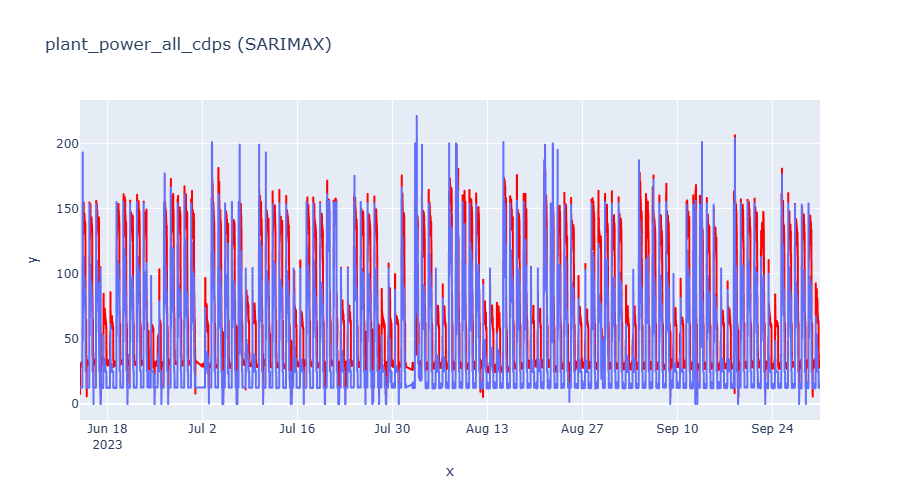

In [12]:
import pandas as pd
import numpy as np
import plotly.express as px
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


cdps_feature = ['plant_cooling_rate'] + \
                [f'chiller_{i}_cond_water_flow_rate' for i in range(1, 6)]

cdps_target = ['plant_power_all_cdps']

X = chiller_data[cdps_feature]
y = chiller_data[cdps_target]

train_size = int(0.6 * len(X))
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

# Train the SARIMAX model
sarimax_model = SARIMAX(y_train, exog=X_train, order=(2, 1, 3), seasonal_order=(0, 0, 0, 0))
sarimax_result = sarimax_model.fit()

# Predict
y_pred_sarimax = sarimax_result.forecast(steps=len(X_test), exog=X_test, index=X_test.index)
y_pred_sarimax = np.maximum(y_pred_sarimax, 0)  # Clip negative predictions to zero

# Performance Metrics for SARIMAX
mse_sarimax = mean_squared_error(y_test, y_pred_sarimax)
mae_sarimax = mean_absolute_error(y_test, y_pred_sarimax)
r2_sarimax = r2_score(y_test, y_pred_sarimax)

def cvrmse(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return rmse / np.mean(y_true)

cvrmse_sarimax = cvrmse(y_test, y_pred_sarimax)

# Print metrics for SARIMAX
print(f"SARIMAX MSE: {mse_sarimax}")
print(f"SARIMAX MAE: {mae_sarimax}")
print(f"SARIMAX R²: {r2_sarimax}")
print(f"SARIMAX CvRMSE: {cvrmse_sarimax}")

# Plotting
y_pred_sarimax_df = pd.DataFrame(y_pred_sarimax.values, index=y_test.index, columns=[cdps_target[0]])
fig = px.line(x=X_test.index, y=y_pred_sarimax_df[cdps_target[0]], title=f'{cdps_target[0]} (SARIMAX)')
fig.update_traces(line_color='red', name=f'{cdps_target[0]} (SARIMAX)')
fig.add_trace(px.line(x=X_test.index, y=y_test[cdps_target[0]]).data[0])
fig.show()

# CTs

### Linear Regression

Linear Regression MSE: 20.491371191440866
Linear Regression MAE: 3.3922438079654724
Linear Regression R²: 0.9379787461237624


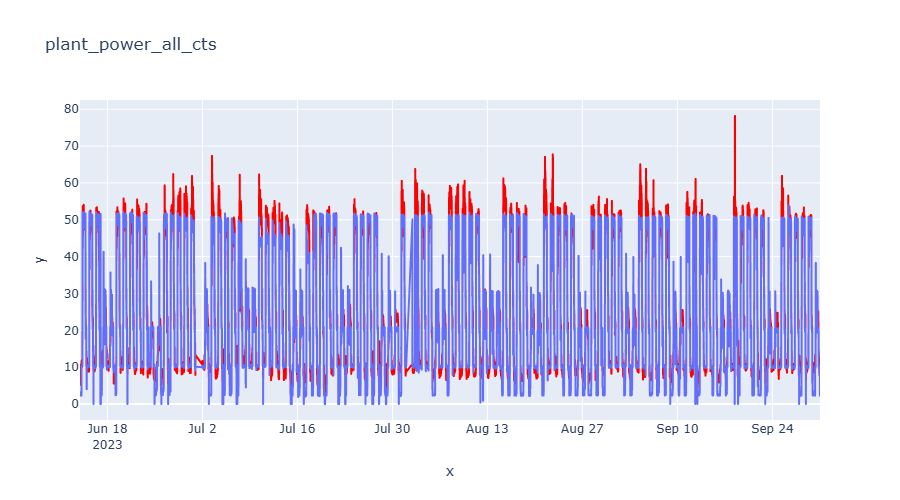

In [13]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

cts_feature = ['plant_cooling_rate',
            'outdoor_weather_station_wetbulb_temperature',
            'outdoor_weather_station_relative_humidity',
            # 'chilled_water_loop_return_water_temperature',
            # 'chilled_water_loop_supply_water_temperature',
            'chilled_water_loop_flow_rate',
            'condenser_water_loop_flow_rate']

cts_target = ['plant_power_all_cts']

X = chiller_data[cts_feature]
y = chiller_data[cts_target]

train_size = int(0.6 * len(X))
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

# Train the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict
y_pred_lr = lr_model.predict(X_test)
y_pred_lr = y_pred_lr.clip(min=0)

# Performance Metrics
mse_lr = mean_squared_error(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

# Print metrics
print(f"Linear Regression MSE: {mse_lr}")
print(f"Linear Regression MAE: {mae_lr}")
print(f"Linear Regression R²: {r2_lr}")


# Plotting
y_pred_lr_df = pd.DataFrame(y_pred_lr, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=y_pred_lr_df[cts_target[0]], title=f'{cts_target[0]}')
fig.update_traces(line_color='red', name=f'{cts_target[0]}')
fig.add_trace(px.line(x=X_test.index, y=y_test[cts_target[0]]).data[0])
fig.show()

### Random Forest

Random Forest MSE: 14.964950405412763
Random Forest MAE: 2.590810088016249
Random Forest R²: 0.9547055694971213


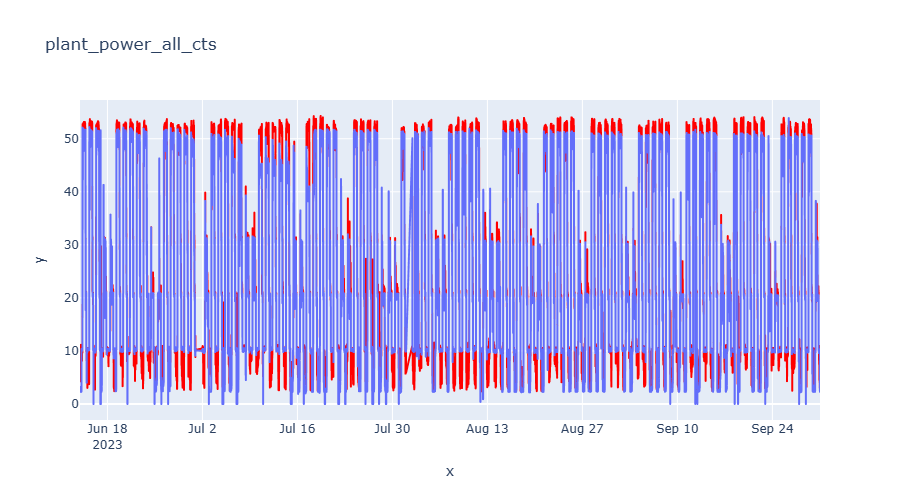

In [14]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

cts_feature = ['plant_cooling_rate',
            'outdoor_weather_station_wetbulb_temperature',
            'outdoor_weather_station_relative_humidity',
            # 'chilled_water_loop_return_water_temperature',
            # 'chilled_water_loop_supply_water_temperature',
            'chilled_water_loop_flow_rate',
            'condenser_water_loop_flow_rate']

cts_target = ['plant_power_all_cts']

X = chiller_data[cts_feature]
y = chiller_data[cts_target]

train_size = int(0.6 * len(X))
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

# Train the model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train.values.ravel())

# Predict
y_pred_rf = rf_model.predict(X_test)
y_pred_rf = np.clip(y_pred_rf, a_min=0, a_max=None)  # Clip predictions to be non-negative

# Performance Metrics
mse_rf = mean_squared_error(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)


# Print metrics
print(f"Random Forest MSE: {mse_rf}")
print(f"Random Forest MAE: {mae_rf}")
print(f"Random Forest R²: {r2_rf}")

# Plotting
y_pred_rf_df = pd.DataFrame(y_pred_rf, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=y_pred_rf_df[cts_target[0]], title=f'{cts_target[0]}')
fig.update_traces(line_color='red', name=f'{cts_target[0]}')
fig.add_trace(px.line(x=X_test.index, y=y_test[cts_target[0]]).data[0])
fig.show()


### SARIMAX

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.



SARIMAX MSE: 113.38682154841692
SARIMAX MAE: 8.815534678315673
SARIMAX R²: 0.6568119927273873


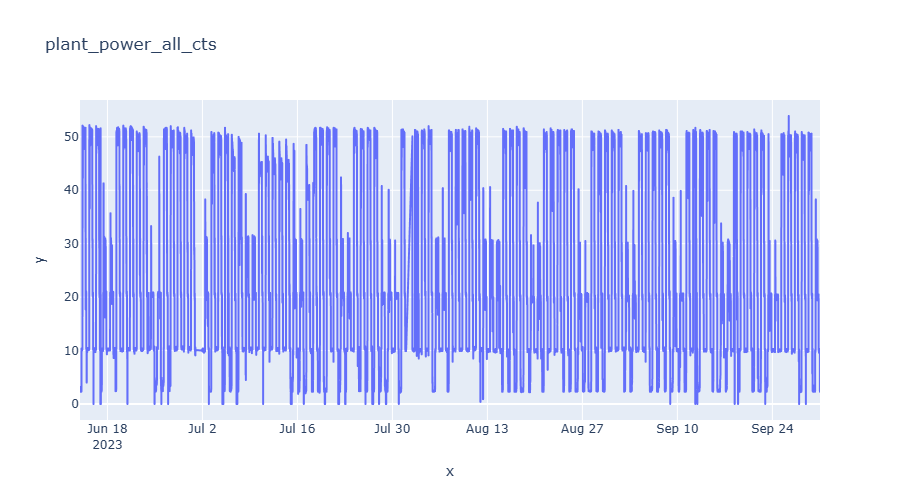

In [15]:
import pandas as pd
import numpy as np
import plotly.express as px
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

cts_feature = ['plant_cooling_rate',
               'outdoor_weather_station_wetbulb_temperature',
               'outdoor_weather_station_relative_humidity',
               'chilled_water_loop_flow_rate',
               'condenser_water_loop_flow_rate']

cts_target = ['plant_power_all_cts']

X = chiller_data[cts_feature]
y = chiller_data[cts_target]

train_size = int(0.6 * len(X))
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

# Train the model
sarimax_model = SARIMAX(y_train, exog=X_train, order=(1, 1, 1), seasonal_order=(0, 0, 0, 0))
sarimax_result = sarimax_model.fit(disp=False)

# Predict
y_pred_sarimax = sarimax_result.forecast(steps=len(X_test), exog=X_test, index=X_test.index)
y_pred_sarimax = np.clip(y_pred_sarimax, a_min=0, a_max=None)  # Clip predictions to be non-negative

# Performance Metrics
mse_sarimax = mean_squared_error(y_test, y_pred_sarimax)
mae_sarimax = mean_absolute_error(y_test, y_pred_sarimax)
r2_sarimax = r2_score(y_test, y_pred_sarimax)


# Print metrics
print(f"SARIMAX MSE: {mse_sarimax}")
print(f"SARIMAX MAE: {mae_sarimax}")
print(f"SARIMAX R²: {r2_sarimax}")

# Plotting
y_pred_sarimax_df = pd.DataFrame(y_pred_sarimax, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=y_pred_sarimax_df[cts_target[0]], title=f'{cts_target[0]}')
fig.update_traces(line_color='red', name=f'{cts_target[0]}')
fig.add_trace(px.line(x=X_test.index, y=y_test[cts_target[0]]).data[0])
fig.show()

# Chiller (return temp)

### Linear Regression

Linear Regression MSE: 3.128359940296195
Linear Regression MAE: 1.33508783145483
Linear Regression R²: 0.537946452427988
Linear Regression CvRMSE: 0.03179220590988768


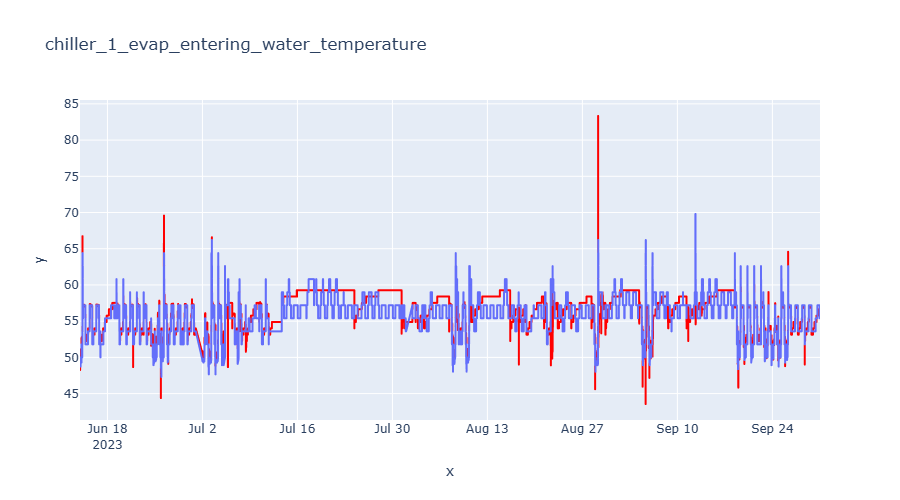

Linear Regression MSE: 1.557797509074893
Linear Regression MAE: 0.9330795319621541
Linear Regression R²: 0.8352078577637256
Linear Regression CvRMSE: 0.022977730955507567


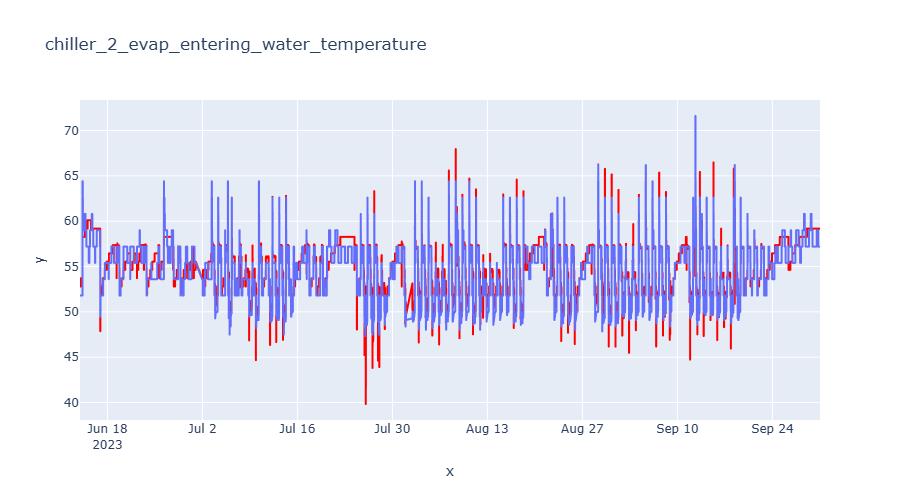

Linear Regression MSE: 1.7767876273752292
Linear Regression MAE: 0.8314358634222365
Linear Regression R²: 0.8104507322985262
Linear Regression CvRMSE: 0.024840937096718516


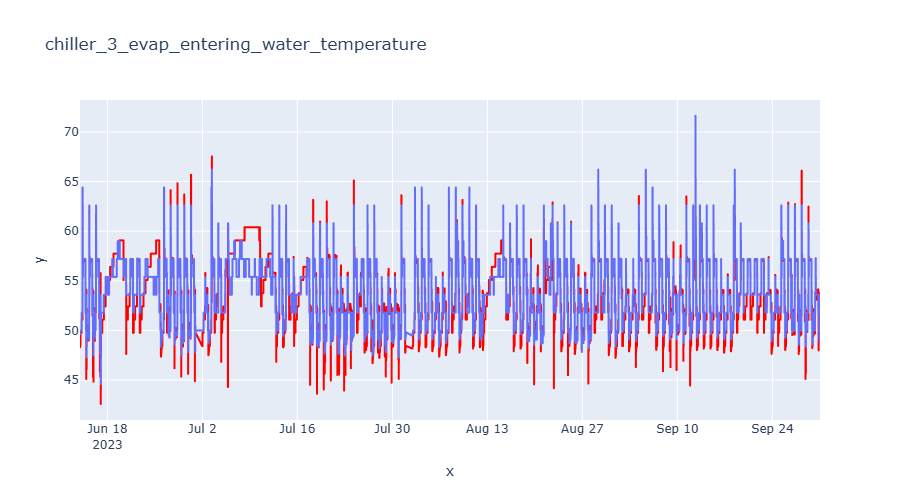

Linear Regression MSE: 1.663401869372232
Linear Regression MAE: 0.9780741074752776
Linear Regression R²: 0.7997620831186087
Linear Regression CvRMSE: 0.024047919843280856


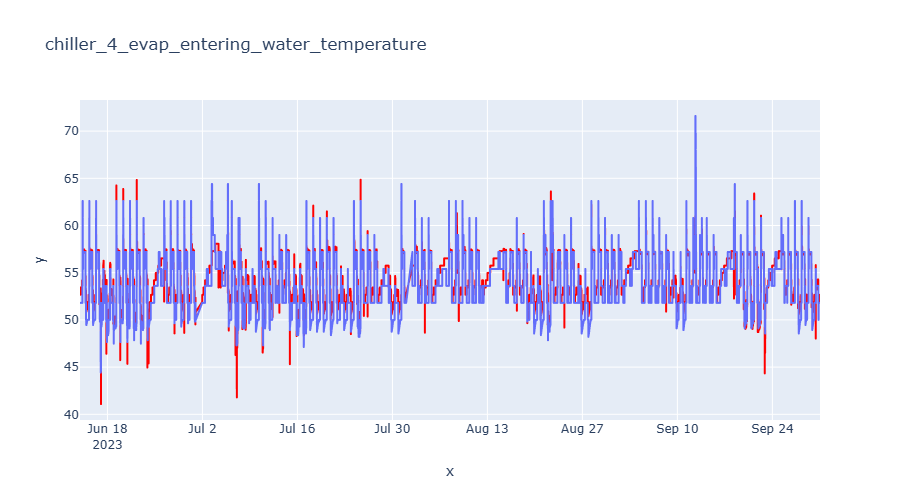

Linear Regression MSE: 1.856868003718283
Linear Regression MAE: 1.0391597091344869
Linear Regression R²: 0.7177595950954232
Linear Regression CvRMSE: 0.025170897489919537


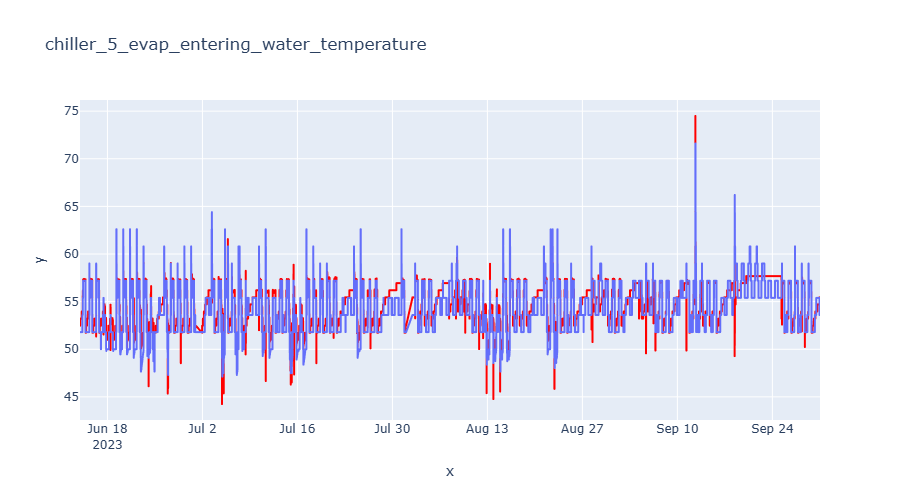

In [16]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

for chiller_id in range (1,6):
    chillers_feature = [f'chiller_{chiller_id}_cooling_rate',
            f'chiller_{chiller_id}_evap_leaving_water_temperature',
            f'chiller_{chiller_id}_evap_water_flow_rate',
            f'chiller_{chiller_id}_cond_water_flow_rate',
            f'chiller_{chiller_id}_status_read']

    chillers_target = [f'chiller_{chiller_id}_evap_entering_water_temperature']

    X = chiller_data[chillers_feature]
    y = chiller_data[chillers_target]

    train_size = int(0.6 * len(X))
    X_train, y_train = X[:train_size], y[:train_size]
    X_test, y_test = X[train_size:], y[train_size:]

    # Train the model
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)

    # Predict
    y_pred_lr = lr_model.predict(X_test)
    y_pred_lr = y_pred_lr.clip(min=0)

    # Performance Metrics
    mse_lr = mean_squared_error(y_test, y_pred_lr)
    mae_lr = mean_absolute_error(y_test, y_pred_lr)
    r2_lr = r2_score(y_test, y_pred_lr)

    def cvrmse(y_true, y_pred):
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        return rmse / np.mean(y_true)

    cvrmse_lr = cvrmse(y_test, y_pred_lr)

    # Print metrics
    print(f"Linear Regression MSE: {mse_lr}")
    print(f"Linear Regression MAE: {mae_lr}")
    print(f"Linear Regression R²: {r2_lr}")
    print(f"Linear Regression CvRMSE: {cvrmse_lr}")

    # Plotting
    y_pred_lr_df = pd.DataFrame(y_pred_lr, index=y_test.index, columns=y_test.columns)
    fig = px.line(x=X_test.index, y=y_pred_lr_df[chillers_target[0]], title=f'{chillers_target[0]}')
    fig.update_traces(line_color='red', name=f'{chillers_target[0]}')
    fig.add_trace(px.line(x=X_test.index, y=y_test[chillers_target[0]]).data[0])
    fig.show()

### Random Forest

Random Forest MSE: 2.2206840308336826
Random Forest MAE: 1.099162292535114
Random Forest R²: 0.6720086709759909


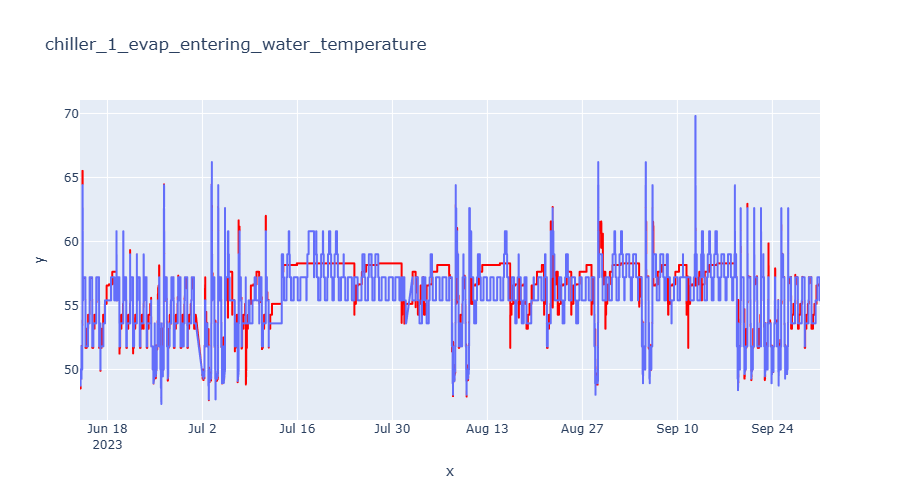

Random Forest MSE: 1.253432022642732
Random Forest MAE: 0.6911986006384105
Random Forest R²: 0.867405264833485


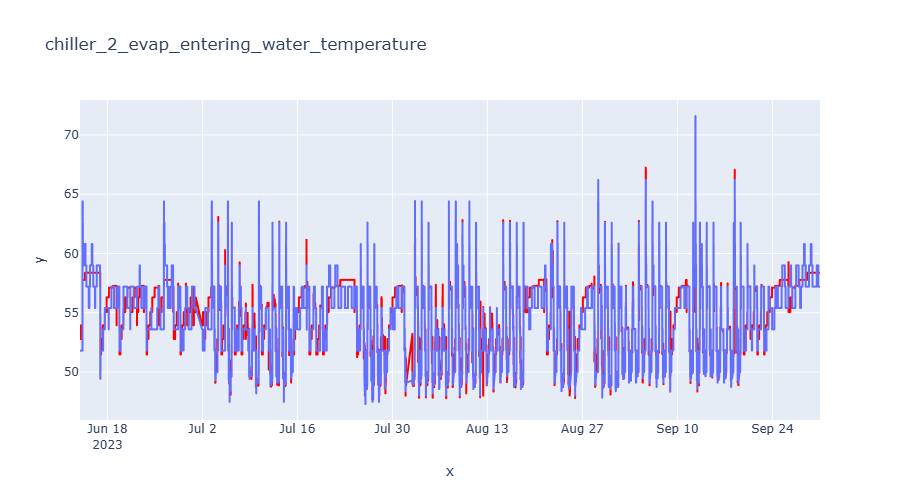

Random Forest MSE: 1.019659885061824
Random Forest MAE: 0.5642521969743172
Random Forest R²: 0.8912217861379665


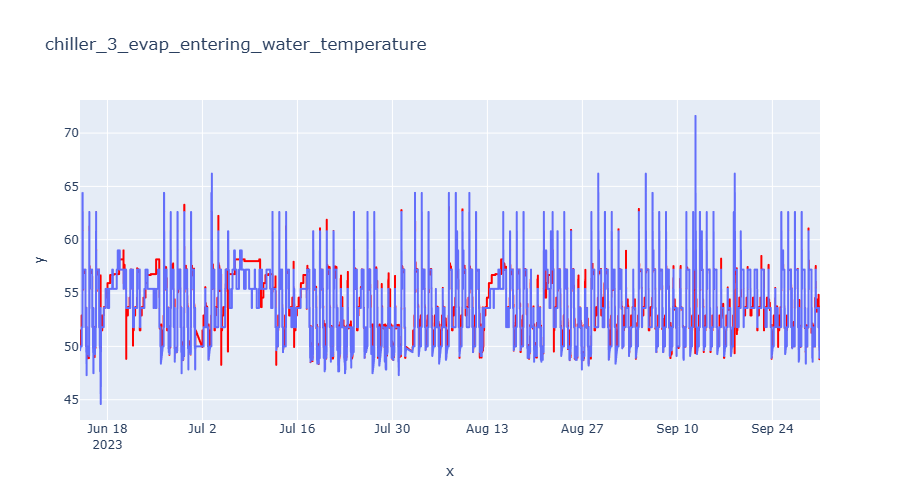

Random Forest MSE: 1.4245506161294161
Random Forest MAE: 0.7126215234605009
Random Forest R²: 0.8285146523410427


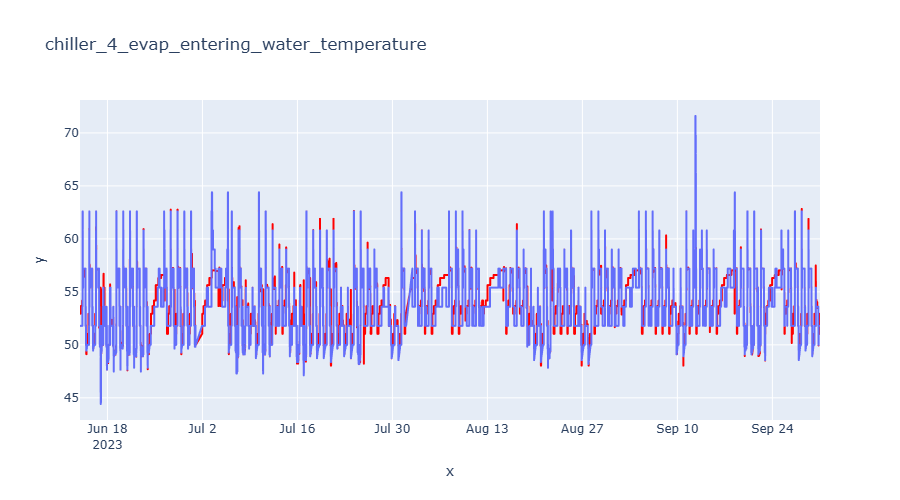

Random Forest MSE: 1.9291014246495197
Random Forest MAE: 0.9656846513772446
Random Forest R²: 0.7067802524978607


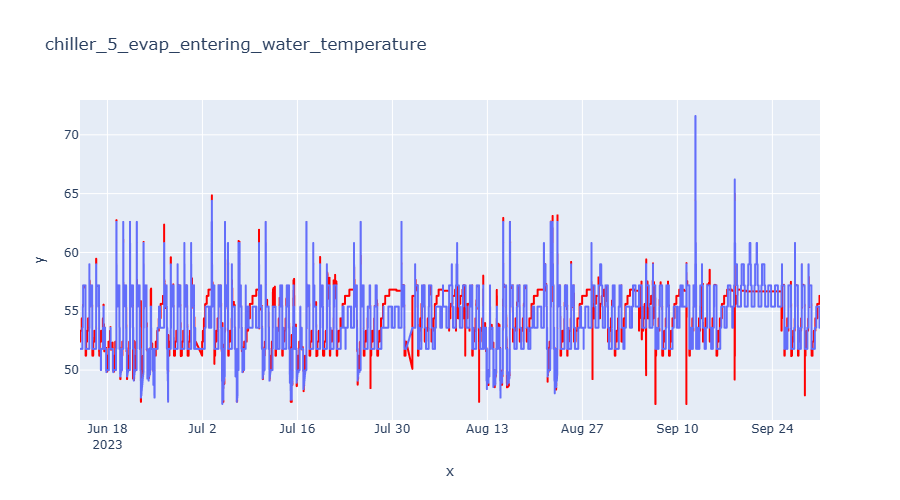

In [17]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

for chiller_id in range(1, 6):
    chillers_feature = [f'chiller_{chiller_id}_cooling_rate',
                        f'chiller_{chiller_id}_evap_leaving_water_temperature',
                        f'chiller_{chiller_id}_evap_water_flow_rate',
                        f'chiller_{chiller_id}_cond_water_flow_rate',
                        f'chiller_{chiller_id}_status_read']

    chillers_target = [f'chiller_{chiller_id}_evap_entering_water_temperature']

    X = chiller_data[chillers_feature]
    y = chiller_data[chillers_target]

    train_size = int(0.6 * len(X))
    X_train, y_train = X[:train_size], y[:train_size]
    X_test, y_test = X[train_size:], y[train_size:]

    # Train the model
    rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_model.fit(X_train, y_train.values.ravel())

    # Predict
    y_pred_rf = rf_model.predict(X_test)
    y_pred_rf = np.clip(y_pred_rf, a_min=0, a_max=None)  # Clip predictions to be non-negative

    # Performance Metrics
    mse_rf = mean_squared_error(y_test, y_pred_rf)
    mae_rf = mean_absolute_error(y_test, y_pred_rf)
    r2_rf = r2_score(y_test, y_pred_rf)


    # Print metrics
    print(f"Random Forest MSE: {mse_rf}")
    print(f"Random Forest MAE: {mae_rf}")
    print(f"Random Forest R²: {r2_rf}")

    # Plotting
    y_pred_rf_df = pd.DataFrame(y_pred_rf, index=y_test.index, columns=y_test.columns)
    fig = px.line(x=X_test.index, y=y_pred_rf_df[chillers_target[0]], title=f'{chillers_target[0]}')
    fig.update_traces(line_color='red', name=f'{chillers_target[0]}')
    fig.add_trace(px.line(x=X_test.index, y=y_test[chillers_target[0]]).data[0])
    fig.show()


### SARIMAX

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.



SARIMAX MSE: 62.137178816292874
SARIMAX MAE: 7.041579713083342
SARIMAX R²: -8.177557715902172


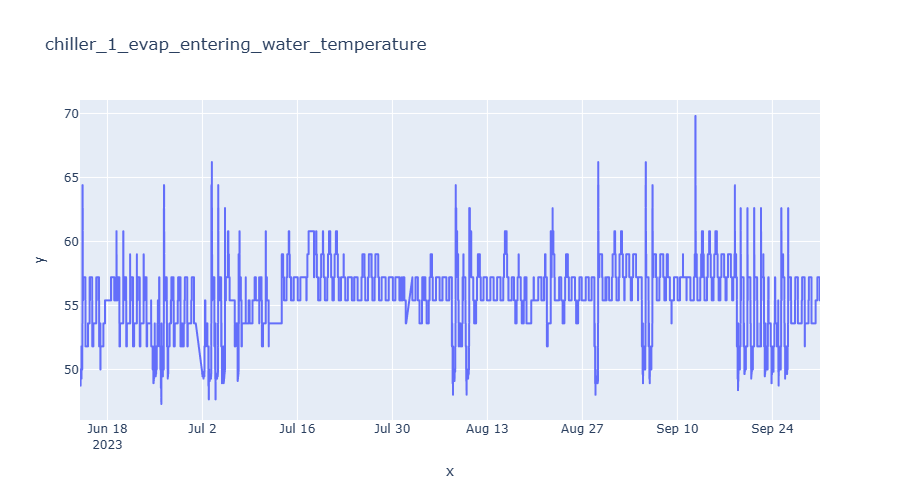

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



SARIMAX MSE: 34.90595858415331
SARIMAX MAE: 5.201692713367533
SARIMAX R²: -2.692538766035959


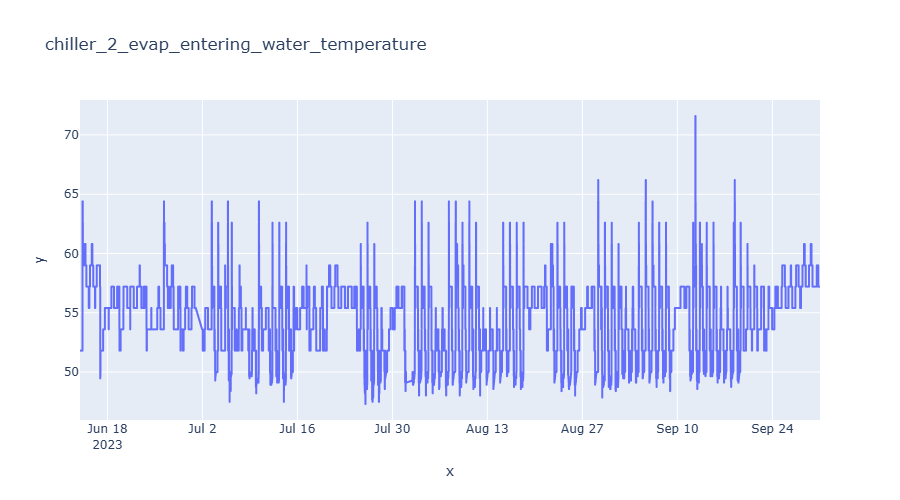

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.



SARIMAX MSE: 38.119001620410884
SARIMAX MAE: 5.977052265128739
SARIMAX R²: -3.0665686384444193


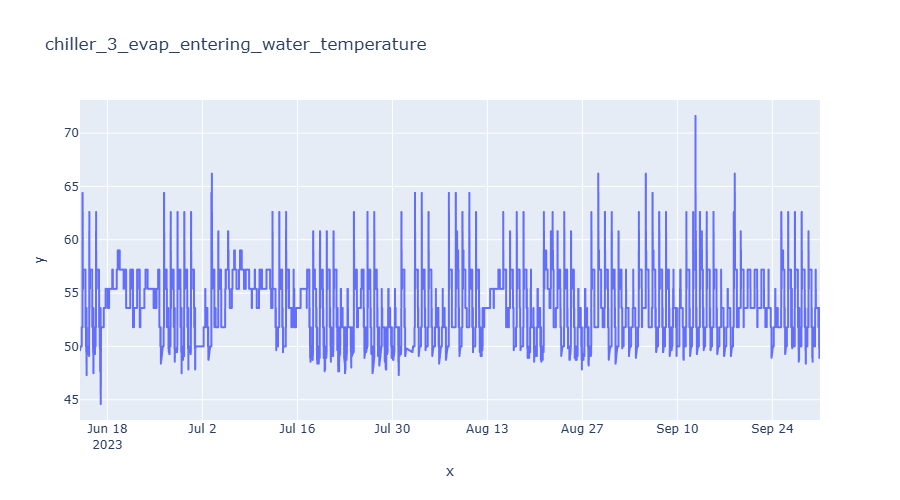

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



SARIMAX MSE: 3.284943591254197
SARIMAX MAE: 1.2871025147858906
SARIMAX R²: 0.6045632303913069


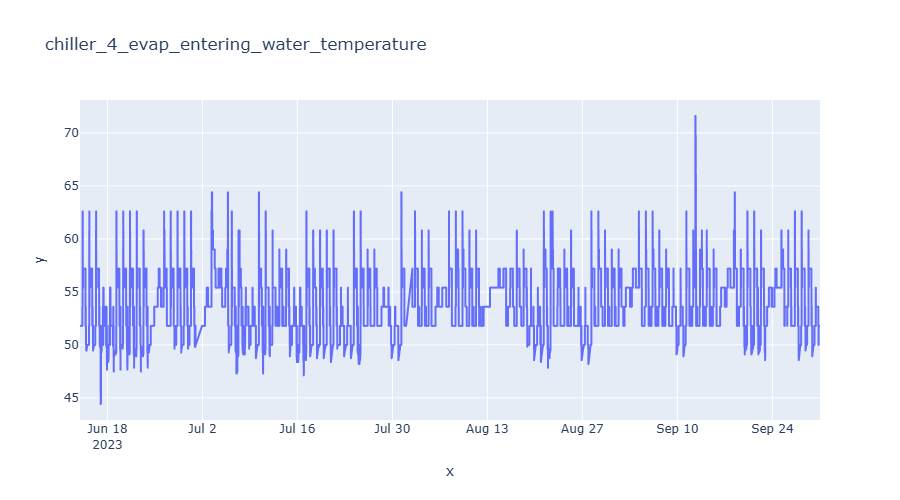

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



SARIMAX MSE: 8.434623871716855
SARIMAX MAE: 2.167204449111094
SARIMAX R²: -0.28204678631123037


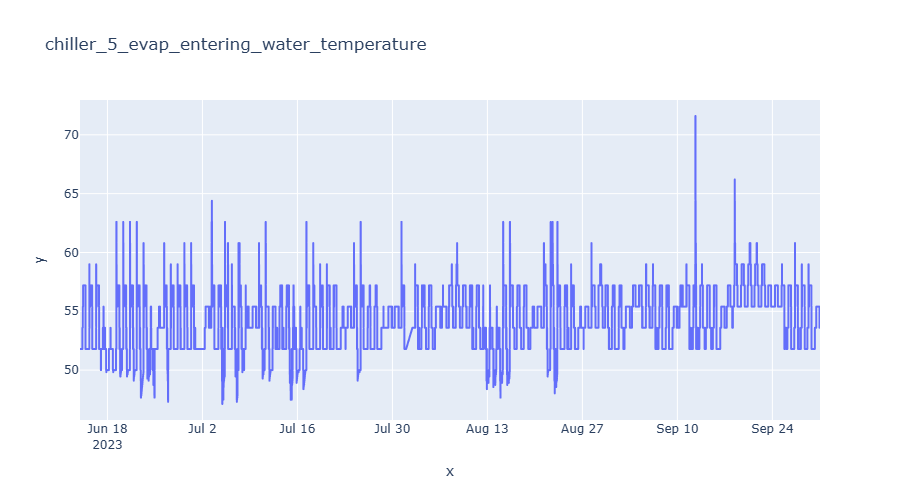

In [18]:
import pandas as pd
import numpy as np
import plotly.express as px
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

for chiller_id in range(1, 6):
    chillers_feature = [f'chiller_{chiller_id}_cooling_rate',
                        f'chiller_{chiller_id}_evap_leaving_water_temperature',
                        f'chiller_{chiller_id}_evap_water_flow_rate',
                        f'chiller_{chiller_id}_cond_water_flow_rate',
                        f'chiller_{chiller_id}_status_read']

    chillers_target = [f'chiller_{chiller_id}_evap_entering_water_temperature']

    X = chiller_data[chillers_feature]
    y = chiller_data[chillers_target]

    train_size = int(0.6 * len(X))
    X_train, y_train = X[:train_size], y[:train_size]
    X_test, y_test = X[train_size:], y[train_size:]

    # Train the SARIMAX model
    model = SARIMAX(y_train, exog=X_train, order=(1, 0, 0), seasonal_order=(1, 0, 0, 12))
    sarimax_model = model.fit()

    # Predict
    y_pred_sarimax = sarimax_model.forecast(steps=len(X_test), exog=X_test, index=X_test.index)
    y_pred_sarimax = np.clip(y_pred_sarimax, a_min=0, a_max=None)  # Clip predictions to be non-negative

    # Performance Metrics
    mse_sarimax = mean_squared_error(y_test, y_pred_sarimax)
    mae_sarimax = mean_absolute_error(y_test, y_pred_sarimax)
    r2_sarimax = r2_score(y_test, y_pred_sarimax)


    # Print metrics
    print(f"SARIMAX MSE: {mse_sarimax}")
    print(f"SARIMAX MAE: {mae_sarimax}")
    print(f"SARIMAX R²: {r2_sarimax}")

    # Plotting
    y_pred_sarimax_df = pd.DataFrame(y_pred_sarimax, index=y_test.index, columns=y_test.columns)
    fig = px.line(x=X_test.index, y=y_pred_sarimax_df[chillers_target[0]], title=f'{chillers_target[0]}')
    fig.update_traces(line_color='red', name=f'{chillers_target[0]}')
    fig.add_trace(px.line(x=X_test.index, y=y_test[chillers_target[0]]).data[0])
    fig.show()


# Chiller (power)

### Linear Regression

Linear Regression MSE: 324.4970061755647
Linear Regression MAE: 6.644728898127901
Linear Regression R²: 0.9744860828097345
Linear Regression CvRMSE: 0.2894704292002026


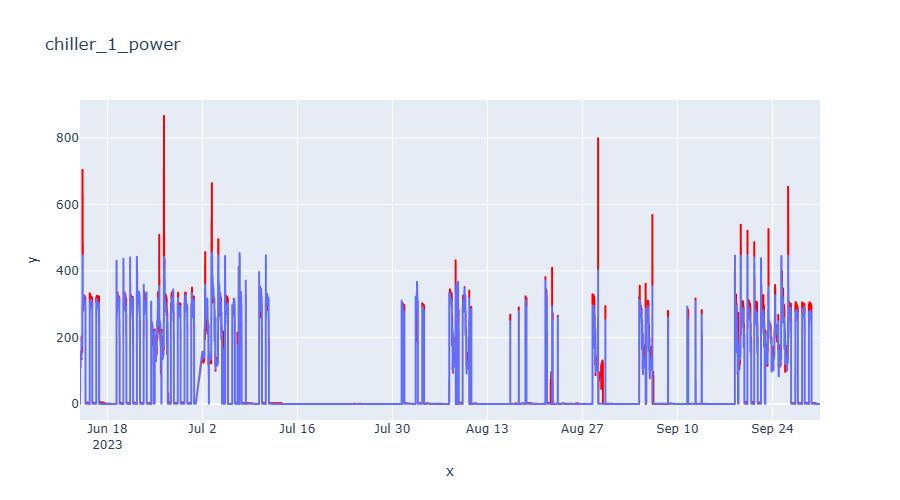

Linear Regression MSE: 467.28699117185636
Linear Regression MAE: 11.498689246404826
Linear Regression R²: 0.976742827157111
Linear Regression CvRMSE: 0.17385443406331547


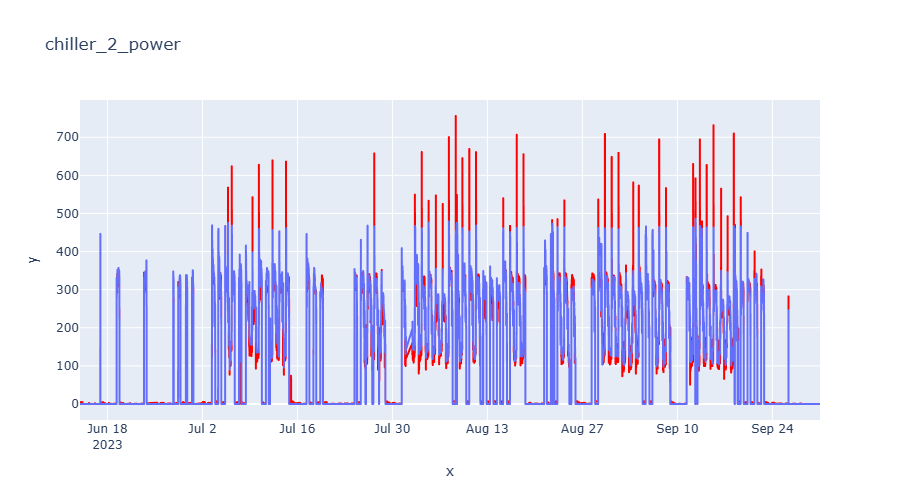

Linear Regression MSE: 4140.2062670002815
Linear Regression MAE: 23.94078257027445
Linear Regression R²: 0.7775184608029071
Linear Regression CvRMSE: 0.42739778859693744


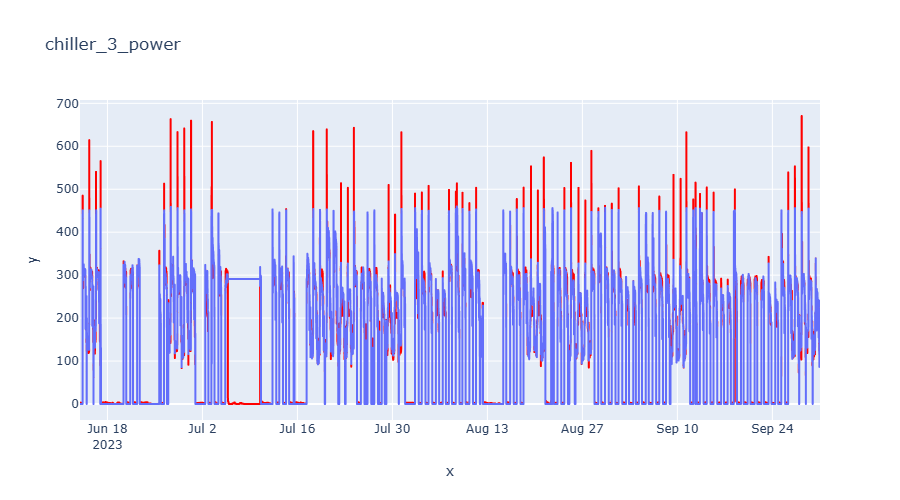

Linear Regression MSE: 373.1170605604579
Linear Regression MAE: 10.3536152662436
Linear Regression R²: 0.9803067308365717
Linear Regression CvRMSE: 0.15636521937581097


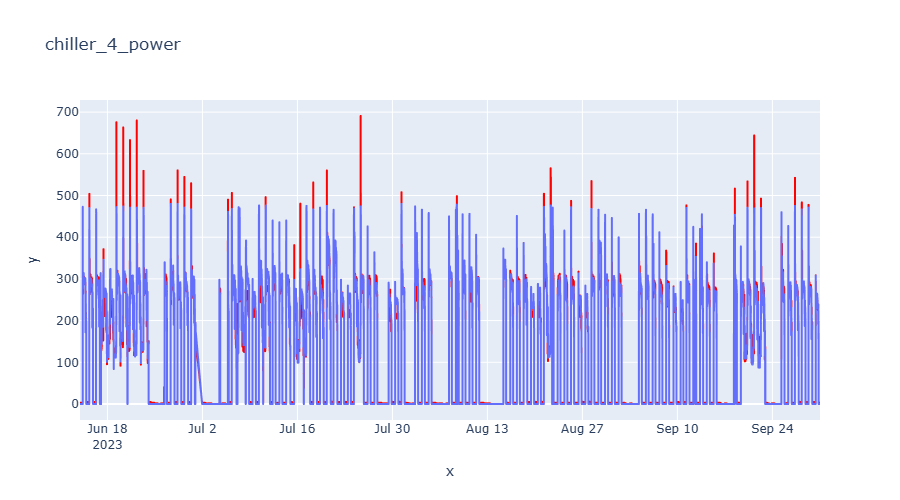

Linear Regression MSE: 232.8862065666822
Linear Regression MAE: 6.386001212045432
Linear Regression R²: 0.9848243404595135
Linear Regression CvRMSE: 0.17464049294466386


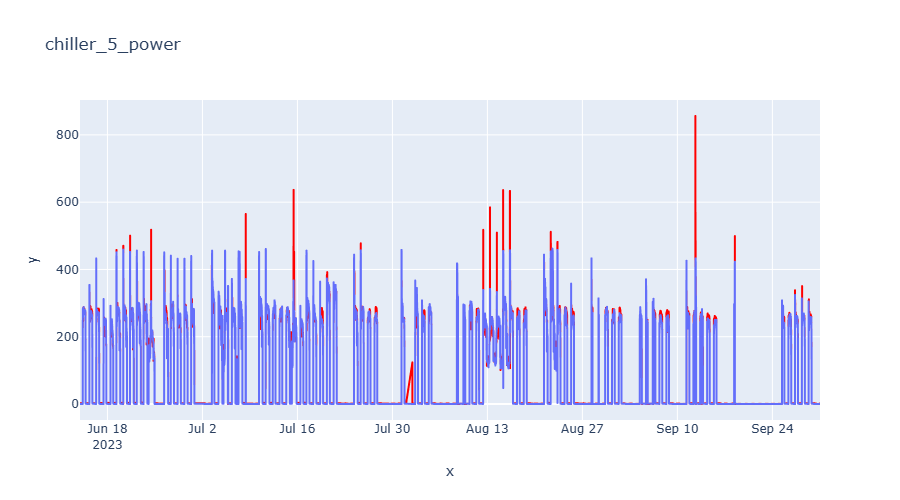

In [19]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

for chiller_id in range (1,6):
    chillers_feature = [f'chiller_{chiller_id}_cooling_rate',
            f'chiller_{chiller_id}_evap_leaving_water_temperature',
            f'chiller_{chiller_id}_evap_entering_water_temperature',
            f'chiller_{chiller_id}_evap_water_flow_rate',
            f'chiller_{chiller_id}_cond_water_flow_rate',
            f'chiller_{chiller_id}_status_read']

    chillers_target = [f'chiller_{chiller_id}_power']

    X = chiller_data[chillers_feature]
    y = chiller_data[chillers_target]

    train_size = int(0.6 * len(X))
    X_train, y_train = X[:train_size], y[:train_size]
    X_test, y_test = X[train_size:], y[train_size:]

    # Train the model
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)

    # Predict
    y_pred_lr = lr_model.predict(X_test)
    y_pred_lr = y_pred_lr.clip(min=0)

    # Performance Metrics
    mse_lr = mean_squared_error(y_test, y_pred_lr)
    mae_lr = mean_absolute_error(y_test, y_pred_lr)
    r2_lr = r2_score(y_test, y_pred_lr)

    def cvrmse(y_true, y_pred):
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        return rmse / np.mean(y_true)

    cvrmse_lr = cvrmse(y_test, y_pred_lr)

    # Print metrics
    print(f"Linear Regression MSE: {mse_lr}")
    print(f"Linear Regression MAE: {mae_lr}")
    print(f"Linear Regression R²: {r2_lr}")
    print(f"Linear Regression CvRMSE: {cvrmse_lr}")

    # Plotting
    y_pred_lr_df = pd.DataFrame(y_pred_lr, index=y_test.index, columns=y_test.columns)
    fig = px.line(x=X_test.index, y=y_pred_lr_df[chillers_target[0]], title=f'{chillers_target[0]}')
    fig.update_traces(line_color='red', name=f'{chillers_target[0]}')
    fig.add_trace(px.line(x=X_test.index, y=y_test[chillers_target[0]]).data[0])
    fig.show()

### Random forest

Random Forest MSE for Chiller 1: 256.886694232013
Random Forest MAE for Chiller 1: 5.823366758747391
Random Forest R² for Chiller 1: 0.9798020144433303


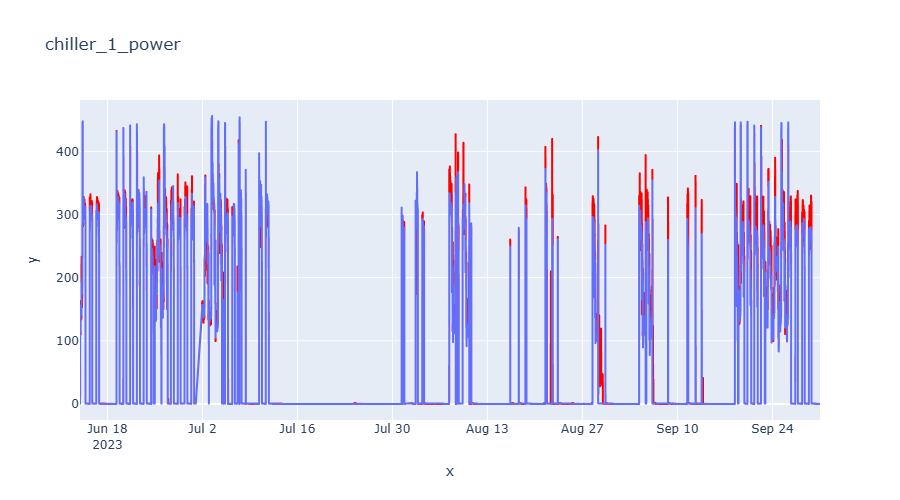

Random Forest MSE for Chiller 2: 381.6088611853352
Random Forest MAE for Chiller 2: 10.037678208383939
Random Forest R² for Chiller 2: 0.9810070825624562


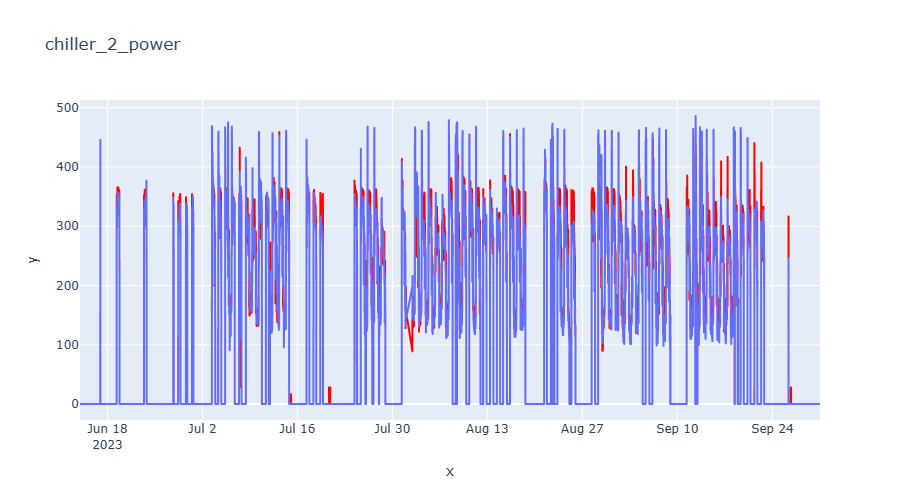

Random Forest MSE for Chiller 3: 4057.4216603427926
Random Forest MAE for Chiller 3: 23.35892852506758
Random Forest R² for Chiller 3: 0.7819670427148244


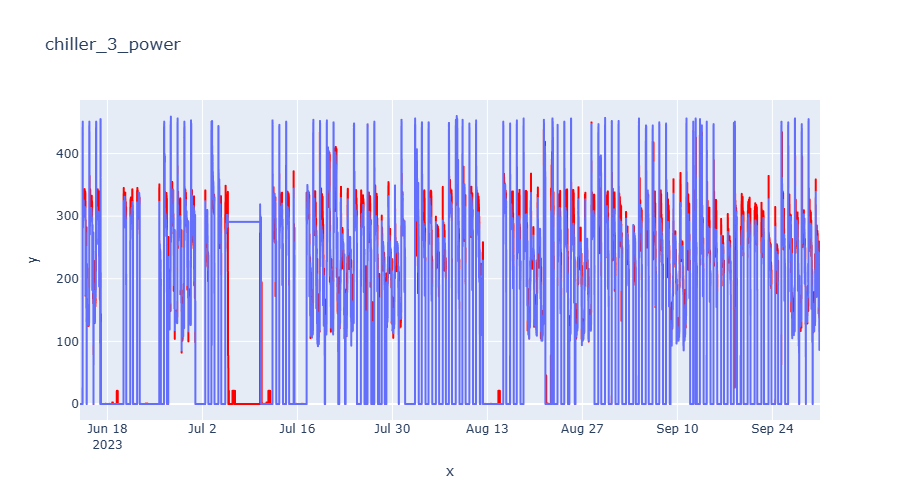

Random Forest MSE for Chiller 4: 264.73807505394853
Random Forest MAE for Chiller 4: 7.700441315875228
Random Forest R² for Chiller 4: 0.9860270174673492


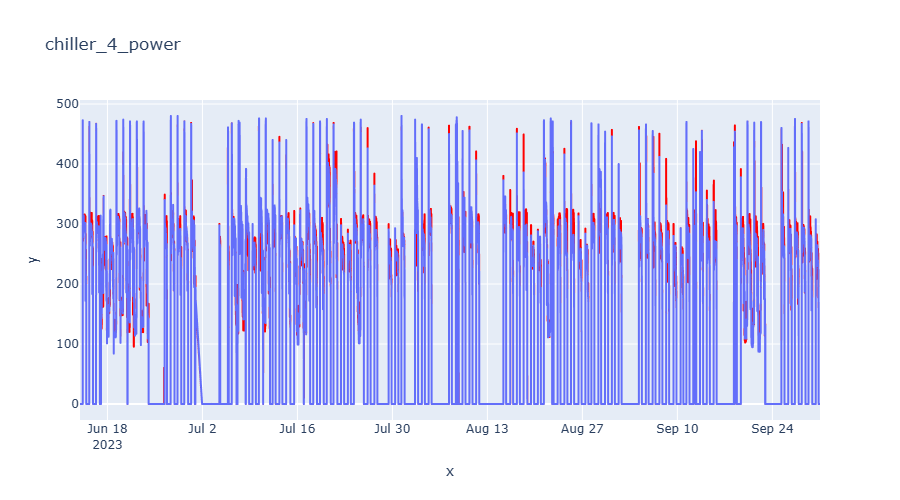

Random Forest MSE for Chiller 5: 178.65013380973133
Random Forest MAE for Chiller 5: 5.393336725520827
Random Forest R² for Chiller 5: 0.9883585479469666


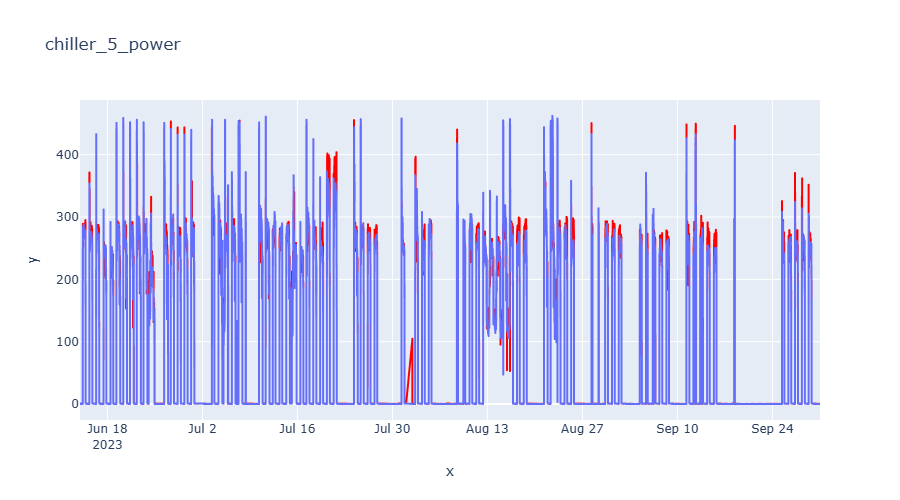

In [20]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

for chiller_id in range(1, 6):
    chillers_feature = [f'chiller_{chiller_id}_cooling_rate',
                        f'chiller_{chiller_id}_evap_leaving_water_temperature',
                        f'chiller_{chiller_id}_evap_entering_water_temperature',
                        f'chiller_{chiller_id}_evap_water_flow_rate',
                        f'chiller_{chiller_id}_cond_water_flow_rate',
                        f'chiller_{chiller_id}_status_read']

    chillers_target = [f'chiller_{chiller_id}_power']

    X = chiller_data[chillers_feature]
    y = chiller_data[chillers_target]

    train_size = int(0.6 * len(X))
    X_train, y_train = X[:train_size], y[:train_size]
    X_test, y_test = X[train_size:], y[train_size:]

    # Train the model
    rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_model.fit(X_train, y_train.values.ravel())

    # Predict
    y_pred_rf = rf_model.predict(X_test)
    y_pred_rf = np.clip(y_pred_rf, a_min=0, a_max=None)  # Clip predictions to be non-negative

    # Performance Metrics
    mse_rf = mean_squared_error(y_test, y_pred_rf)
    mae_rf = mean_absolute_error(y_test, y_pred_rf)
    r2_rf = r2_score(y_test, y_pred_rf)

    # Print metrics
    print(f"Random Forest MSE for Chiller {chiller_id}: {mse_rf}")
    print(f"Random Forest MAE for Chiller {chiller_id}: {mae_rf}")
    print(f"Random Forest R² for Chiller {chiller_id}: {r2_rf}")

    # Plotting
    y_pred_rf_df = pd.DataFrame(y_pred_rf, index=y_test.index, columns=y_test.columns)
    fig = px.line(x=X_test.index, y=y_pred_rf_df[chillers_target[0]], title=f'{chillers_target[0]}')
    fig.update_traces(line_color='red', name=f'{chillers_target[0]}')
    fig.add_trace(px.line(x=X_test.index, y=y_test[chillers_target[0]]).data[0])
    fig.show()


### SARIMAX

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



SARIMAX MSE: 393.4024998948907
SARIMAX MAE: 8.108996230000919
SARIMAX R²: 0.9690683161516407


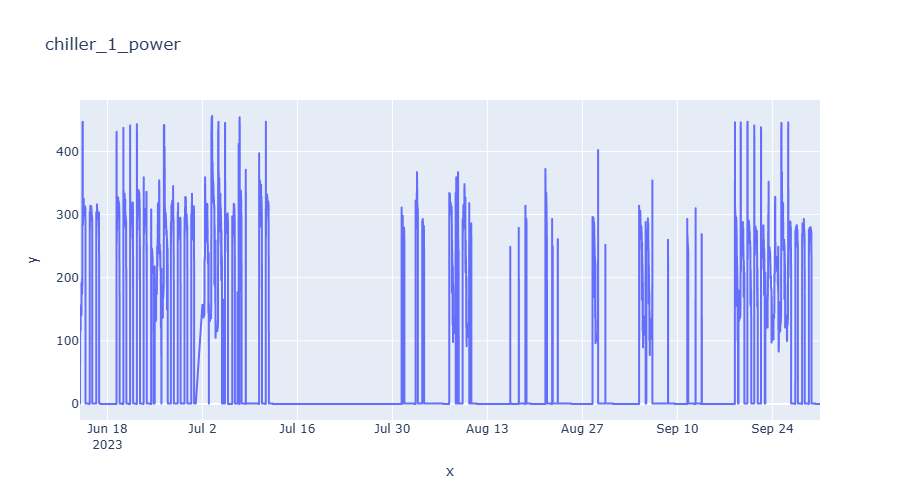

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning:

Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Pyth

SARIMAX MSE: 912.383450907398
SARIMAX MAE: 17.00682588689181
SARIMAX R²: 0.9545900912766029


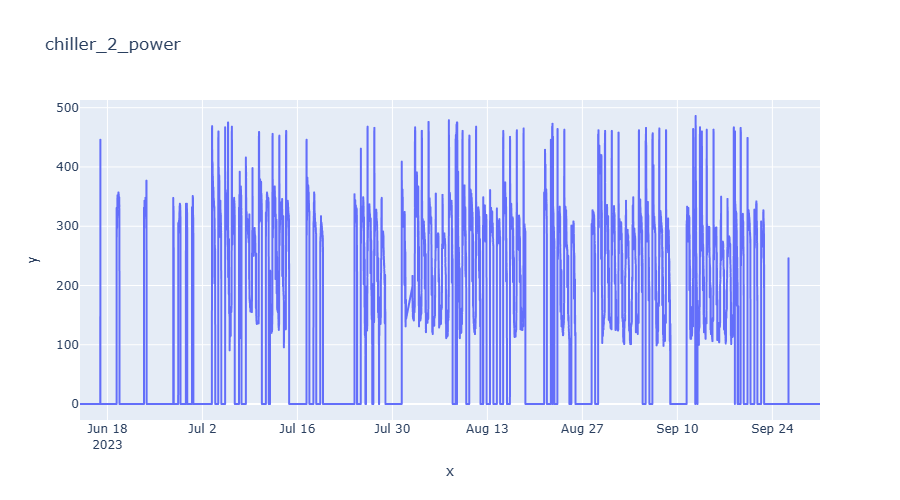

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



SARIMAX MSE: 5729.843771467636
SARIMAX MAE: 40.411908261075446
SARIMAX R²: 0.692096388579543


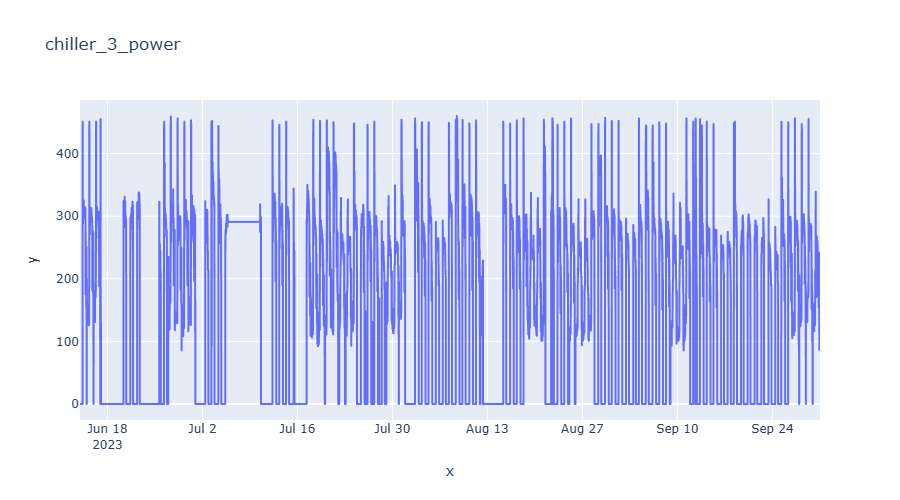

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



SARIMAX MSE: 795.8130905784952
SARIMAX MAE: 14.805311257610951
SARIMAX R²: 0.9579966636395534


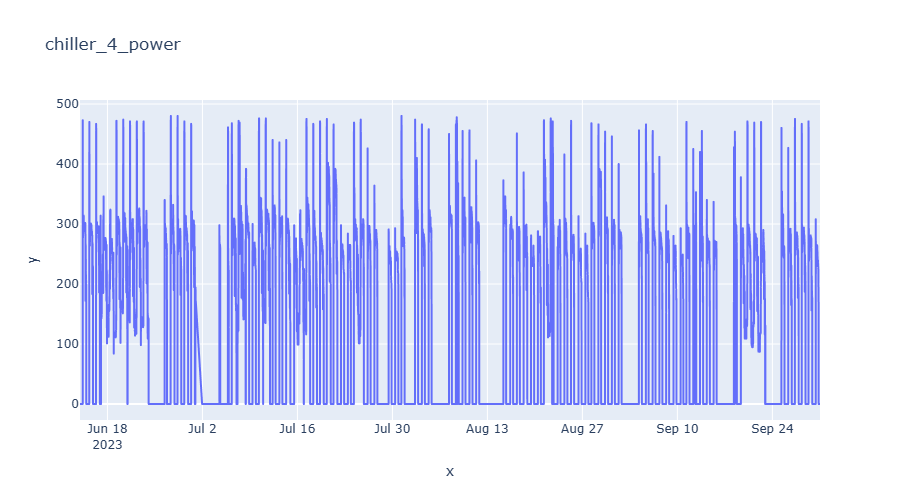

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



SARIMAX MSE: 292.0578139355143
SARIMAX MAE: 7.4529087736702575
SARIMAX R²: 0.9809685167027913


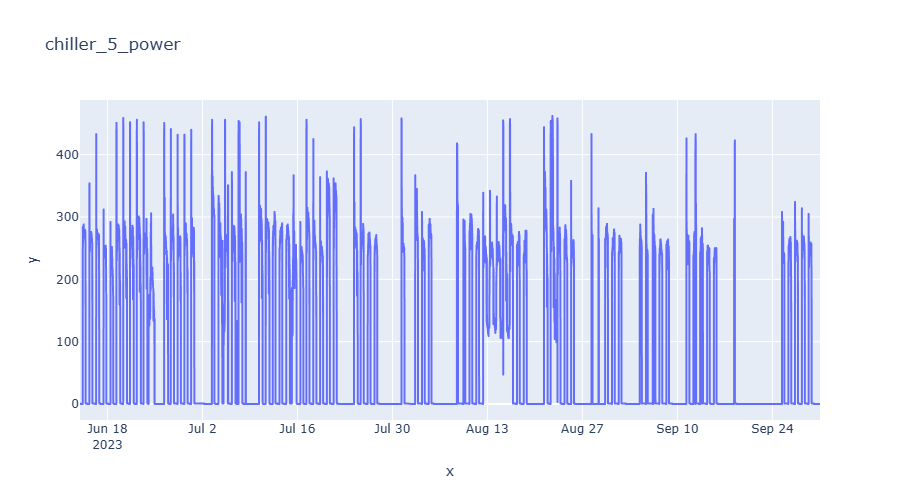

: 

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

for chiller_id in range(1, 6):
    chillers_feature = [f'chiller_{chiller_id}_cooling_rate',
                        f'chiller_{chiller_id}_evap_leaving_water_temperature',
                        f'chiller_{chiller_id}_evap_entering_water_temperature',
                        f'chiller_{chiller_id}_evap_water_flow_rate',
                        f'chiller_{chiller_id}_cond_water_flow_rate',
                        f'chiller_{chiller_id}_status_read']

    chillers_target = [f'chiller_{chiller_id}_power']

    X = chiller_data[chillers_feature]
    y = chiller_data[chillers_target]

    train_size = int(0.6 * len(X))
    X_train, y_train = X[:train_size], y[:train_size]
    X_test, y_test = X[train_size:], y[train_size:]

    # Train the SARIMAX model
    model = SARIMAX(y_train, exog=X_train, order=(2, 1, 3), seasonal_order=(0, 0, 0, 0))
    sarimax_model = model.fit()

    # Predict
    y_pred_sarimax = sarimax_model.forecast(steps=len(X_test), exog=X_test, index=X_test.index)
    y_pred_sarimax = np.clip(y_pred_sarimax, a_min=0, a_max=None)  # Clip predictions to be non-negative

    # Performance Metrics
    mse_sarimax = mean_squared_error(y_test, y_pred_sarimax)
    mae_sarimax = mean_absolute_error(y_test, y_pred_sarimax)
    r2_sarimax = r2_score(y_test, y_pred_sarimax)


    # Print metrics
    print(f"SARIMAX MSE: {mse_sarimax}")
    print(f"SARIMAX MAE: {mae_sarimax}")
    print(f"SARIMAX R²: {r2_sarimax}")

    # Plotting
    y_pred_sarimax_df = pd.DataFrame(y_pred_sarimax, index=y_test.index, columns=y_test.columns)
    fig = px.line(x=X_test.index, y=y_pred_sarimax_df[chillers_target[0]], title=f'{chillers_target[0]}')
    fig.update_traces(line_color='red', name=f'{chillers_target[0]}')
    fig.add_trace(px.line(x=X_test.index, y=y_test[chillers_target[0]]).data[0])
    fig.show()
